# Notebook 13 — Event features: scoring what happens, not only what is mentioned

**Why.** Notebook 02 extracts nouns, noun phrases, verbs and names one at a time. Courts usually describe scènes à faire as things that happen: "firing a machine gun", "a shootout", "escaping from prison". The pipeline has "gun" and "fire" separately but not the event. This notebook is a first pass at an event-level unit, built with a grammatical parser and counting only, with no language-model judgment.

**What an event is here.** For every verb in a plot summary, the parser gives its grammatical dependents. Three kinds of event are recorded, each as dictionary forms (lemmas):

| Kind | Rule | Example sentence | Event |
|---|---|---|---|
| verb + object | the verb's direct object, or the subject of a passive verb | "The gang robs a bank." / "A bank is robbed." | `rob bank` |
| verb + preposition + object | the object of a preposition attached to the verb | "He escapes from prison." | `escape from prison` |
| subject + verb | the verb's subject, or the agent of a passive verb | "The sheriff arrests him." | `sheriff arrest` |

Only common nouns count as subjects and objects, so names of people and places never enter. A verb's particle is kept ("blow up bridge"). The verbs *be*, *have* and *do* are skipped, and so are events about the summary itself ("the film ends", "the story begins"). An event counts once per film.

**Scores.** Exactly the two quantities of Notebook 03, at the film level: prevalence P(e|g) = films of genre g with the event ÷ films of genre g, and distinctiveness P(g|e) = (films of g with the event + α·P(g)) ÷ (films with the event + α), α = 1, with P(g) the genre's share of film-genre pairs. Events in fewer than 10 films are dropped.

**Status.** Exploratory, added November 2026 for the CogForum talk. It reads `01c_union/movies_union.parquet` and writes only to `v4_rebuild/13_event_elements/`. Nothing in Notebooks 02 to 12 depends on it, and the Study 1 predictors are unaffected. The parser is spaCy's small English model (`en_core_web_sm`); Notebook 02 used the large one, which differs in word vectors and name recognition, not in the kind of parse used here.

In [1]:
import os, re, sys, shutil, tempfile, time
from pathlib import Path
import numpy as np
import pandas as pd

try:
    from google.colab import drive  # type: ignore
    drive.mount('/content/drive')
except Exception:
    pass

_CANDS = [
    Path('/content/drive/MyDrive/DGK Lab/Reasoning Lab/'
         'DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild'),
    Path('/Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/'
         'My Drive/DGK Lab/Reasoning Lab/'
         'DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild'),
    Path.cwd() / 'v4_rebuild',
    Path.cwd().parent / 'v4_rebuild',
]
V4 = next((c for c in _CANDS if c.exists()), None)
assert V4 is not None, 'Could not locate v4_rebuild; set V4 manually.'
OUT = V4 / '13_event_elements'
OUT.mkdir(parents=True, exist_ok=True)
TMP = Path(tempfile.mkdtemp())
def read_parquet(p):
    local = TMP / p.name          # Drive sometimes serves partial parquet files; read a local copy
    shutil.copy(p, local)
    return pd.read_parquet(local)

MIN_FILMS = 10        # an event must appear in at least this many films
ALPHA     = 1.0       # smoothing, as in Notebook 03
SKIP_VERBS = {'be', 'have', 'do'}
# Words about the summary itself ("the film ends", "the story begins"), not about what happens in the story.
META_WORDS = {'film', 'movie', 'story', 'scene', 'cartoon', 'plot', 'audience', 'viewer', 'credit', 'credits',
              'narrator', 'flashback', 'episode', 'sequence', 'short', 'sequel', 'title'}
N_PROCESS = max(1, min(8, (os.cpu_count() or 2) - 1))
print('V4 =', V4); print('OUT =', OUT); print('processes =', N_PROCESS)

V4 = /Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild
OUT = /Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild/13_event_elements
processes = 8


## Load the films

In [2]:
films = read_parquet(V4 / '01c_union' / 'movies_union.parquet')[['union_id', 'plot', 'genres_canonical', 'year']]
films['genres'] = films['genres_canonical'].map(lambda g: [str(x) for x in list(g)] if g is not None else [])
fg = films[['union_id', 'genres']].explode('genres').dropna().rename(columns={'genres': 'genre'})
fg = fg[fg['genre'].str.len() > 0]
N_g = fg.groupby('genre')['union_id'].nunique()
P_PRIOR = N_g / N_g.sum()                      # each genre's share of film-genre pairs
print(f'{len(films):,} films, {len(N_g)} genres, {len(fg):,} film-genre pairs')
print(N_g.sort_values(ascending=False).to_string())

45,958 films, 17 genres, 100,130 film-genre pairs
genre
Drama              22364
Comedy             14724
Romance             8220
Action              7775
Thriller            7447
Adventure           6146
Crime               5564
Horror              4363
Family              4164
Music               2926
History             2882
Animation           2835
Mystery             2681
Science Fiction     2590
Fantasy             2429
War                 1658
Western             1362


## Extract events with the parser

The parse of all summaries takes a few minutes on several processor cores. The result is cached in `event_index.parquet`; delete that file to force a fresh parse.

In [3]:
PATH_INDEX = OUT / 'event_index.parquet'

def events_of(doc):
    out = set()
    for tok in doc:
        if tok.pos_ != 'VERB':
            continue
        v = tok.lemma_.lower()
        if v in SKIP_VERBS or not v.isalpha():
            continue
        prt = [c.lemma_.lower() for c in tok.children if c.dep_ == 'prt']
        if prt:
            v = v + ' ' + prt[0]
        def nouns(head):
            # the noun itself and any nouns joined to it by "and"/"or"
            res = [head] + [c for c in head.conjuncts]
            return [n.lemma_.lower() for n in res if n.pos_ == 'NOUN' and n.lemma_.isalpha() and len(n.lemma_) > 1]
        for c in tok.children:
            if c.dep_ in ('dobj', 'nsubjpass'):
                for n in nouns(c):
                    out.add((f'{v} {n}', 'verb_object'))
            elif c.dep_ == 'nsubj':
                for n in nouns(c):
                    out.add((f'{n} {v}', 'subject_verb'))
            elif c.dep_ == 'prep':
                for gc in c.children:
                    if gc.dep_ == 'pobj':
                        for n in nouns(gc):
                            out.add((f'{v} {c.lemma_.lower()} {n}', 'verb_prep_object'))
            elif c.dep_ == 'agent':
                for gc in c.children:
                    if gc.dep_ == 'pobj':
                        for n in nouns(gc):
                            out.add((f'{n} {v}', 'subject_verb'))
    return out

if PATH_INDEX.exists():
    idx = read_parquet(PATH_INDEX)
    print(f'loaded cached event index: {len(idx):,} rows')
else:
    import spacy
    try:
        nlp = spacy.load('en_core_web_sm', disable=['ner'])
    except OSError:
        import subprocess
        subprocess.run([sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm'], check=True)
        nlp = spacy.load('en_core_web_sm', disable=['ner'])
    nlp.max_length = 2_000_000
    t0 = time.time()
    rows = []
    texts = films['plot'].fillna('').astype(str).tolist()
    ids = films['union_id'].tolist()
    for uid, doc in zip(ids, nlp.pipe(texts, batch_size=64, n_process=N_PROCESS)):
        for ev, kind in events_of(doc):
            rows.append((uid, ev, kind))
    idx = pd.DataFrame(rows, columns=['union_id', 'event', 'event_type'])
    idx.to_parquet(PATH_INDEX, index=False)
    print(f'parsed {len(texts):,} summaries in {(time.time() - t0) / 60:.1f} min; {len(idx):,} event rows')
print(idx['event_type'].value_counts().to_string())
print(f"{idx[['event', 'event_type']].drop_duplicates().shape[0]:,} distinct events before the frequency rule")

loaded cached event index: 1,696,367 rows
event_type
verb_object         705386
verb_prep_object    660813
subject_verb        330168


776,376 distinct events before the frequency rule


## Score every event in every genre

In [4]:
is_meta = idx['event'].map(lambda e: any(w in META_WORDS for w in e.split()))
print(f'{int(is_meta.sum()):,} event rows are about the summary itself ("film end", "story begin") and are set aside')
idx_story = idx[~is_meta]
tot = idx_story.groupby(['event', 'event_type'])['union_id'].nunique().rename('total_film_count')
keep = tot[tot >= MIN_FILMS]
print(f'{len(keep):,} events appear in at least {MIN_FILMS} films')
ix = idx_story.merge(keep.reset_index(), on=['event', 'event_type'])
cells_ = (ix.merge(fg, on='union_id')
            .groupby(['event', 'event_type', 'genre'])['union_id'].nunique().rename('film_count').reset_index())
sc = cells_.merge(keep.reset_index(), on=['event', 'event_type'])
sc['films_in_genre'] = sc['genre'].map(N_g)
sc['p_prior_g'] = sc['genre'].map(P_PRIOR)
sc['prevalence'] = sc['film_count'] / sc['films_in_genre']
sc['distinctiveness_raw'] = sc['film_count'] / sc['total_film_count']
sc['distinctiveness'] = (sc['film_count'] + ALPHA * sc['p_prior_g']) / (sc['total_film_count'] + ALPHA)
sc['lift'] = sc['distinctiveness_raw'] / (sc['films_in_genre'] / len(films))    # 1 = no association with the genre
for m in ['prevalence', 'distinctiveness']:
    sc[f'p_{m}'] = sc.groupby(['genre', 'event_type'])[m].rank(pct=True)
sc.to_parquet(OUT / 'event_scores.parquet', index=False)
print(f'{len(sc):,} (event, genre) cells written to event_scores.parquet')
sc.sort_values('total_film_count', ascending=False).head(10)

41,800 event rows are about the summary itself ("film end", "story begin") and are set aside


18,724 events appear in at least 10 films


235,572 (event, genre) cells written to event_scores.parquet


,event,event_type,genre,film_count,total_film_count,films_in_genre,p_prior_g,prevalence,distinctiveness_raw,distinctiveness,lift,p_prevalence,p_distinctiveness
59092,fall in love,verb_prep_object,Horror,188,5942,4363,0.043573,0.043090,0.031639,0.031641,0.333274,1.0,0.024166
59086,fall in love,verb_prep_object,Comedy,1940,5942,14724,0.147049,0.131758,0.326489,0.326459,1.019071,1.0,0.606662
59084,fall in love,verb_prep_object,Adventure,539,5942,6146,0.061380,0.087699,0.090710,0.090705,0.678304,1.0,0.258673
59083,fall in love,verb_prep_object,Action,892,5942,7775,0.077649,0.114727,0.150118,0.150106,0.887346,1.0,0.396501
59087,fall in love,verb_prep_object,Crime,440,5942,5564,0.055568,0.079080,0.074049,0.074046,0.611637,1.0,0.158185
59088,fall in love,verb_prep_object,Drama,3278,5942,22364,0.223350,0.146575,0.551666,0.551611,1.133673,1.0,0.690512
59089,fall in love,verb_prep_object,Family,412,5942,4164,0.041586,0.098943,0.069337,0.069332,0.765270,1.0,0.203656
59090,fall in love,verb_prep_object,Fantasy,332,5942,2429,0.024258,0.136682,0.055873,0.055868,1.057156,1.0,0.233238
59091,fall in love,verb_prep_object,History,352,5942,2882,0.028783,0.122137,0.059239,0.059234,0.944664,1.0,0.268831
59093,fall in love,verb_prep_object,Music,671,5942,2926,0.029222,0.229323,0.112925,0.112911,1.773686,1.0,0.741434


## What the events look like

For each genre, the most characteristic events (highest distinctiveness among events in at least 1% of the genre's films, with a floor of 8 films) and the most common ones (highest prevalence).

In [5]:
lines = []
def out(s=''):
    print(s); lines.append(s)
out('NOTEBOOK 13 — EVENT ELEMENTS (exploratory)')
out(f'{len(films):,} films; {len(idx):,} event rows; {len(keep):,} events in at least {MIN_FILMS} films; {len(sc):,} (event, genre) cells')
out(idx['event_type'].value_counts().to_string())
tops = []
for g in sorted(N_g.index):
    d = sc[sc['genre'] == g]
    floor = max(8, int(np.ceil(0.01 * N_g[g])))
    char = d[d['film_count'] >= floor].sort_values('distinctiveness', ascending=False).head(15)
    comm = d.sort_values('prevalence', ascending=False).head(15)
    out(''); out(f'{g}  ({N_g[g]:,} films; characteristic events need {floor}+ films)')
    out('  most characteristic: ' + '; '.join(f"{r.event} ({r.film_count}/{r.total_film_count})" for r in char.itertuples()))
    out('  most common:         ' + '; '.join(f"{r.event} ({r.prevalence * 100:.1f}%)" for r in comm.itertuples()))
    tops.append(char.assign(list='characteristic')); tops.append(comm.assign(list='common'))
pd.concat(tops, ignore_index=True).to_parquet(OUT / 'top_events_by_genre.parquet', index=False)
(OUT / 'event_report.txt').write_text('\n'.join(lines))
print('\nwrote', OUT / 'event_report.txt')

NOTEBOOK 13 — EVENT ELEMENTS (exploratory)
45,958 films; 1,696,367 event rows; 18,724 events in at least 10 films; 235,572 (event, genre) cells
event_type
verb_object         705386
verb_prep_object    660813
subject_verb        330168

Action  (7,775 films; characteristic events need 78+ films)
  most characteristic: fight way (104/149); kill member (100/172); avenge death (181/317); order man (87/164); kill officer (83/162); kill in process (99/195); send man (86/173); kill brother (155/315); open fire (115/236); take hostage (174/365); kill family (99/210); hold at gunpoint (102/230); fake death (89/207); seek revenge (165/391); kill son (112/266)
  most common:         fall in love (11.5%); take place (5.7%); save life (4.4%); commit suicide (4.0%); make way (3.5%); kill man (3.4%); take revenge (3.3%); take care (2.8%); kill father (2.4%); avenge death (2.3%); take hostage (2.2%); seek revenge (2.1%); kill brother (2.0%); find way (1.9%); live life (1.8%)

Adventure  (6,146 films;


Comedy  (14,724 films; characteristic events need 148+ films)
  most characteristic: throw party (151/258); get job (396/879); lose job (178/409); get money (187/446); spend day (168/406); take job (191/468); play game (161/409); make money (154/395); spend night (311/808); make deal (150/402); spend time (479/1289); give chance (177/477); tell truth (251/681); give money (182/500); change mind (243/670)
  most common:         fall in love (13.2%); take place (4.6%); spend time (3.3%); take care (2.7%); get job (2.7%); commit suicide (2.6%); spend night (2.1%); live life (1.9%); make way (1.9%); find way (1.7%); tell truth (1.7%); change mind (1.7%); save life (1.5%); go to house (1.4%); take advantage (1.3%)

Crime  (5,564 films; characteristic events need 56+ films)
  most characteristic: investigate murder (91/200); find killer (57/125); solve case (66/155); commit crime (92/218); commit murder (121/291); pull gun (84/203); sentence to year (66/161); rob bank (104/256); tell police


Horror  (4,363 films; characteristic events need 44+ films)
  most characteristic: turn into vampire (59/64); turn into zombie (53/60); drink blood (64/76); spirit possess (60/77); creature attack (47/68); see ghost (71/109); discover corpse (54/85); cover in blood (57/90); hear scream (87/143); see figure (44/80); slit throat (69/132); bleed to death (45/86); hear noise (123/240); stab with knife (46/95); burn to death (49/103)
  most common:         find body (7.1%); commit suicide (6.6%); take place (5.2%); make way (5.1%); fall in love (4.3%); open door (3.8%); enter room (3.4%); discover body (3.4%); find way (3.3%); receive call (3.1%); hear noise (2.8%); call police (2.7%); leave house (2.7%); kill people (2.7%); spend night (2.6%)

Music  (2,926 films; characteristic events need 30+ films)
  most characteristic: write song (35/76); perform song (58/130); sing song (95/320); singe song (47/163); play song (39/137); play music (35/143); express love (30/194); raise money (40/266


Science Fiction  (2,590 films; characteristic events need 26+ films)
  most characteristic: destroy planet (35/48); kill creature (31/48); destroy ship (59/94); creature kill (27/46); travel in time (33/60); use technology (29/58); creature attack (33/68); destroy city (30/63); destroy world (26/59); find cure (30/72); use machine (28/72); use device (43/114); save world (28/88); use ability (26/82); lose contact (31/98)
  most common:         take place (6.8%); make way (5.6%); fall in love (4.8%); use power (4.0%); commit suicide (3.7%); save life (3.4%); take control (3.3%); find way (3.1%); find body (2.7%); take care (2.4%); destroy ship (2.3%); open door (2.0%); regain consciousness (1.9%); take hostage (1.9%); give birth (1.7%)

Thriller  (7,447 films; characteristic events need 75+ films)
  most characteristic: investigate murder (110/200); hold at gunpoint (116/230); kill officer (80/162); point gun (88/182); investigate case (77/162); shoot in head (118/254); fake death (96/

## Figures

The figures below are ordinary matplotlib plots with matplotlib's default look. Each is shown here and saved as a PNG in this notebook's `figures/` folder. The talk's slides use those PNG files as they are.

In [6]:
import matplotlib.pyplot as plt
plt.rcdefaults()                                   # matplotlib's own defaults: white background, boxed axes, DejaVu Sans
plt.rcParams.update({'font.size': 10})            # figures are drawn at the size they have on the slide
BLUE, RED = 'tab:blue', 'tab:red'                  # prevalence is blue, distinctiveness is red, in every figure
FIGDIR = OUT / 'figures'
FIGDIR.mkdir(exist_ok=True)
def wilson(k, n, z=1.96):
    # 95% interval for a proportion k out of n (Wilson score interval)
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n; den = 1 + z * z / n
    mid = (p + z * z / (2 * n)) / den; half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return mid - half, mid + half
def mean_ci(v):
    # 95% interval for a mean, from the spread of the values (t distribution)
    from scipy import stats
    v = np.asarray(v, float); h = stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return v.mean() - h, v.mean() + h
ERR = dict(ecolor='black', capsize=3, lw=1.2)        # error bars: black, thin, small caps
def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGDIR / f'{name}.png', dpi=200, facecolor='white', bbox_inches='tight')
    plt.show()

### The most characteristic events, three genres at a time

For each genre, the five most characteristic events among those in at least 1% of the genre's films. The bar is distinctiveness: of the films with the event, the percentage in this genre. The counts are above each bar (films in this genre / all films with the event), and the black line is a 95% interval for the percentage given those counts.

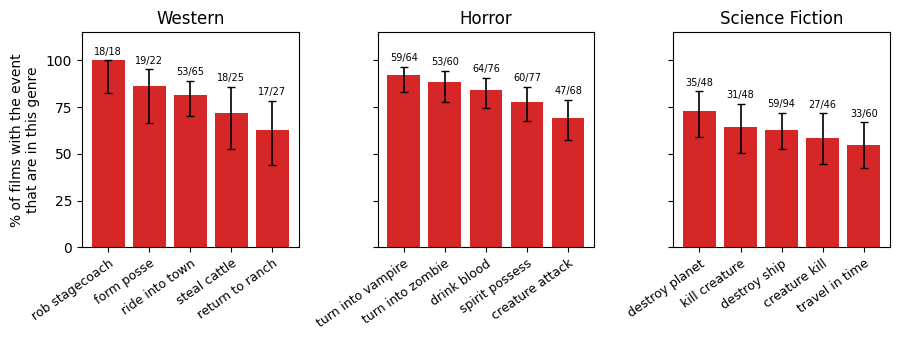

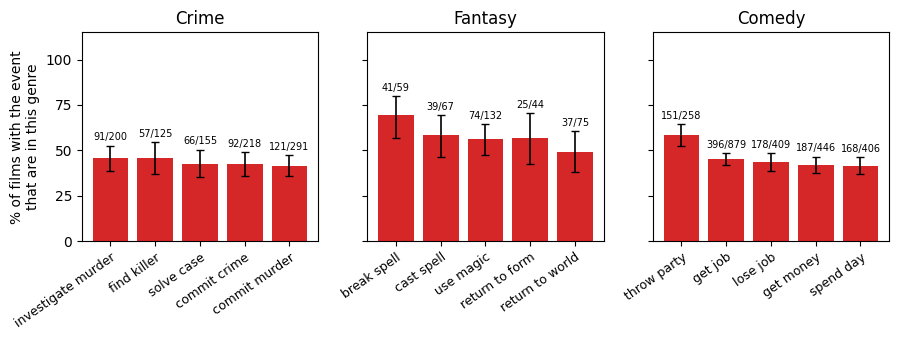

In [7]:
top_tab = pd.concat(tops, ignore_index=True)
def event_bars(genres, name):
    fig, axes = plt.subplots(1, 3, figsize=(9.1, 3.5), sharey=True)
    for ax, g in zip(axes, genres):
        d = top_tab[(top_tab['genre'] == g) & (top_tab['list'] == 'characteristic')].head(5)
        share = 100 * d['film_count'] / d['total_film_count']
        lo, hi = wilson(d['film_count'], d['total_film_count'])
        ax.bar(d['event'], share, color=RED, yerr=[share - 100 * lo, 100 * hi - share], error_kw=ERR)
        for i, r in enumerate(d.itertuples()):
            ax.text(i, 100 * hi[i] + 2, f'{r.film_count}/{r.total_film_count}', ha='center', va='bottom', fontsize=7)
        ax.set_ylim(0, 115); ax.set_yticks([0, 25, 50, 75, 100]); ax.set_title(g)
        plt.setp(ax.get_xticklabels(), rotation=35, ha='right', rotation_mode='anchor', fontsize=9)
    axes[0].set_ylabel('% of films with the event\nthat are in this genre')
    save(fig, name)
event_bars(['Western', 'Horror', 'Science Fiction'], 'events_three_genres')
event_bars(['Crime', 'Fantasy', 'Comedy'], 'events_three_more_genres')

### Events on both dimensions, six genres

Each dot is an event in at least 20 of the genre's films. The most common event and the most characteristic event (among those in at least 1% of the genre's films) are named.

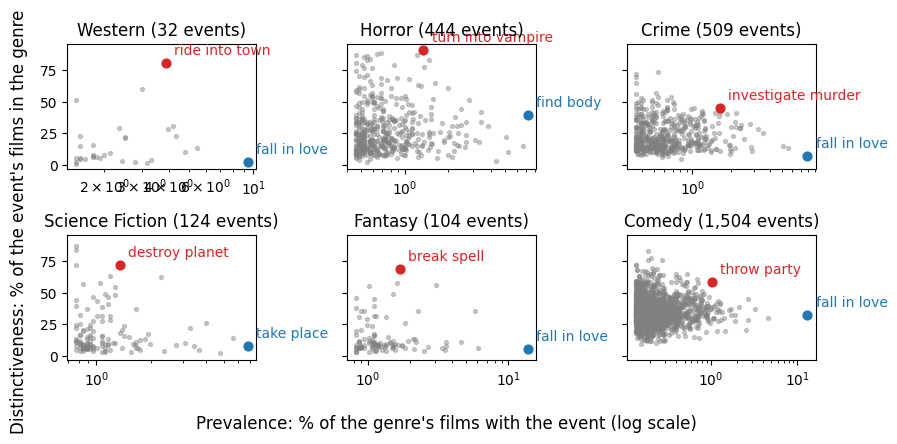

In [8]:
SIX = ['Western', 'Horror', 'Crime', 'Science Fiction', 'Fantasy', 'Comedy']
fig, axes = plt.subplots(2, 3, figsize=(9.1, 4.3), sharey=True)
for ax, g in zip(axes.ravel(), SIX):
    d = sc[(sc['genre'] == g) & (sc['film_count'] >= 20)]
    ax.scatter(100 * d['prevalence'], 100 * d['distinctiveness'], s=8, color='gray', alpha=0.4)
    common = d.nlargest(1, 'prevalence').iloc[0]
    cand = d[d['prevalence'] >= 0.01]
    char = (cand if len(cand) else d).nlargest(1, 'distinctiveness').iloc[0]
    for r, col in [(common, BLUE), (char, RED)]:
        ax.scatter(100 * r['prevalence'], 100 * r['distinctiveness'], s=40, color=col, zorder=3)
        ax.annotate(r['event'], (100 * r['prevalence'], 100 * r['distinctiveness']), xytext=(6, 6), textcoords='offset points', color=col)
    ax.set_xscale('log'); ax.set_title(f'{g} ({len(d):,} events)')
fig.supxlabel("Prevalence: % of the genre's films with the event (log scale)")
fig.supylabel("Distinctiveness: % of the event's films in the genre")
save(fig, 'events_both_dimensions')

## How the two dimensions relate for events

The rank correlation between prevalence and distinctiveness within each genre, for events in at least 20 of the genre's films (the floor the human study used for single features).

In [9]:
from scipy.stats import spearmanr
rows = []
for g, d in sc[sc['film_count'] >= 20].groupby('genre'):
    if len(d) >= 30:
        rows.append({'genre': g, 'n_events': len(d), 'spearman_prevalence_distinctiveness': spearmanr(d['prevalence'], d['distinctiveness'])[0]})
rel = pd.DataFrame(rows)
rel.to_parquet(OUT / 'event_dimension_correlation.parquet', index=False)
print(rel.round(3).to_string(index=False))

          genre  n_events  spearman_prevalence_distinctiveness
         Action       852                               -0.028
      Adventure       582                               -0.047
      Animation        99                               -0.003
         Comedy      1504                               -0.016
          Crime       509                                0.013
          Drama      2895                                0.003
         Family       236                               -0.088
        Fantasy       104                               -0.029
        History       103                               -0.234
         Horror       444                                0.048
          Music       135                               -0.108
        Mystery       161                                0.105
        Romance       752                                0.020
Science Fiction       124                               -0.056
       Thriller       891                              

## What this adds, and what it does not

This gives the pipeline a unit closer to how courts talk: something that happens, with who or what it happens to. The scores are the same two counts as before. It is a first pass. A parser makes mistakes, the events are two or three words and not whole scenes, and nothing here has been checked by hand. It is reported as exploratory.

Outputs in `v4_rebuild/13_event_elements/`: `event_index.parquet` (film, event, kind), `event_scores.parquet` (one row per event and genre), `top_events_by_genre.parquet`, `event_dimension_correlation.parquet`, `event_report.txt`, and the figures in `figures/`.